In [23]:
%matplotlib widget
from pylab import *
import numpy as np
from pyFAI.geometry import Geometry

In [24]:
geometry = Geometry()
geometry.load("../test_data/v1.poni")

shape = (10, 20)
test_index = 65

# Checking test Ouputs

## Pixel Positions with detector as reference

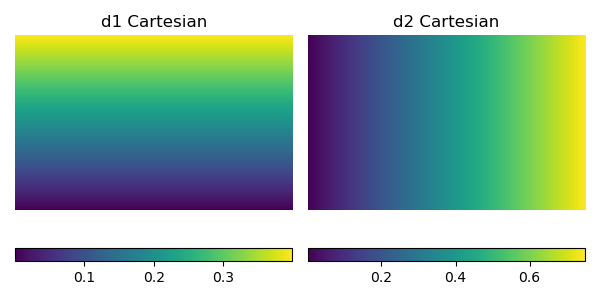

In [25]:
d1_rust = np.loadtxt("test_output/d1_cart.txt").reshape(shape)
d2_rust = np.loadtxt("test_output/d2_cart.txt").reshape(shape)
figure(figsize=(6, 3))
subplot(1, 2, 1)
title("d1 Cartesian"); axis("off")
imshow(d1_rust, origin="lower", aspect="auto")
colorbar(location="bottom")
subplot(1, 2, 2)
title("d2 Cartesian"); axis("off")
imshow(d2_rust, origin="lower", aspect="auto")
colorbar(location="bottom")
tight_layout()

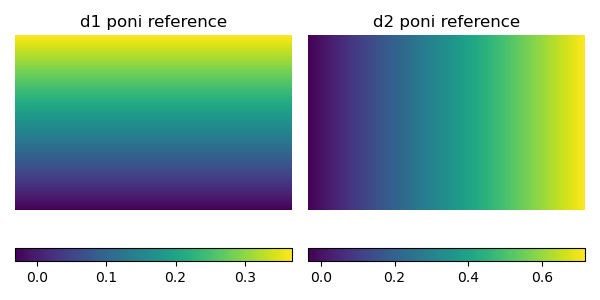

In [26]:
d1_rust = np.loadtxt("test_output/d1_cart_poni.txt").reshape(shape)
d2_rust = np.loadtxt("test_output/d2_cart_poni.txt").reshape(shape)
figure(figsize=(6, 3))
subplot(1, 2, 1)
title("d1 poni reference"); axis("off")
imshow(d1_rust, origin="lower", aspect="auto")
colorbar(location="bottom")
subplot(1, 2, 2)
title("d2 poni reference"); axis("off")
imshow(d2_rust, origin="lower", aspect="auto")
colorbar(location="bottom")
tight_layout()

## Pixel position in x, y, z with sample as reference

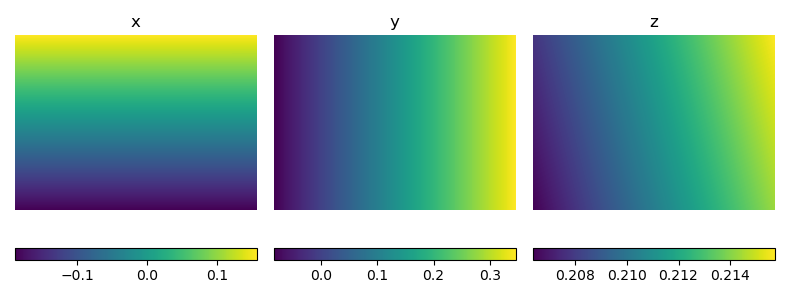

In [27]:
x_rust = np.loadtxt("test_output/x.txt").reshape(shape)
y_rust = np.loadtxt("test_output/y.txt").reshape(shape)
z_rust = np.loadtxt("test_output/z.txt").reshape(shape)

figure(figsize=(8, 3))
subplot(1, 3, 1)
title("x"); axis("off")
imshow(x_rust, origin="lower", aspect="auto")
colorbar(location="bottom")
subplot(1, 3, 2)
title("y"); axis("off")
imshow(y_rust, origin="lower", aspect="auto")
colorbar(location="bottom")
subplot(1, 3, 3)
title("z"); axis("off")
imshow(z_rust, origin="lower", aspect="auto")
colorbar(location="bottom")
tight_layout()

<function matplotlib.pyplot.tight_layout(*, pad=1.08, h_pad=None, w_pad=None, rect=None)>

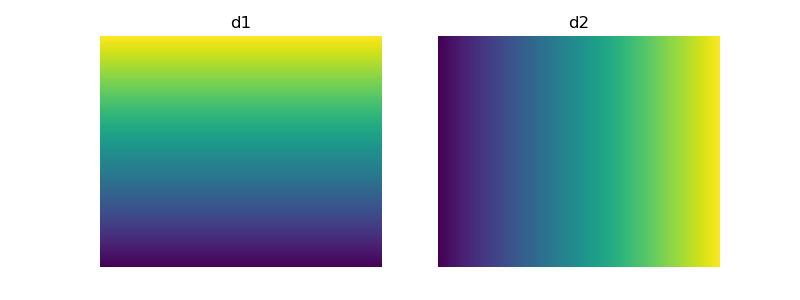

In [28]:
d1 = np.arange(0, shape[0])
d2 = np.arange(0, shape[1])
d2, d1 = np.meshgrid(d2, d1)
figure(figsize=(8, 3))
subplot(1, 2, 1)
title("d1"); axis("off")
imshow(d1, origin="lower", aspect="auto")
subplot(1, 2, 2)
title("d2"); axis("off")
imshow(d2, origin="lower", aspect="auto")
tight_layout

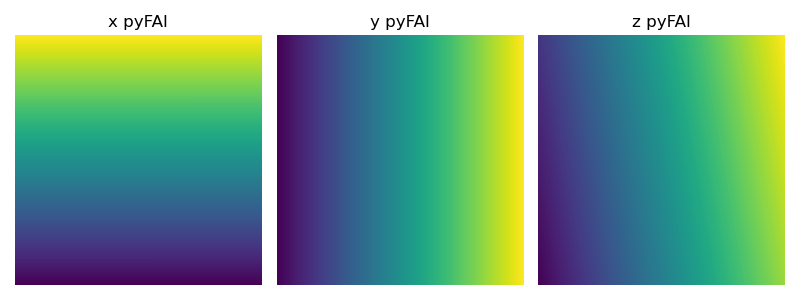

In [29]:
z, x, y = geometry.calc_pos_zyx(None, d1, d2) # does actually return zxy and not zyx
figure(figsize=(8, 3))
subplot(1, 3, 1)
title("x pyFAI"); axis("off")
imshow(x, origin="lower", aspect="auto")
subplot(1, 3, 2)
title("y pyFAI"); axis("off")
imshow(y, origin="lower", aspect="auto")
subplot(1, 3, 3)
title("z pyFAI"); axis("off")
imshow(z, origin="lower", aspect="auto")
tight_layout()

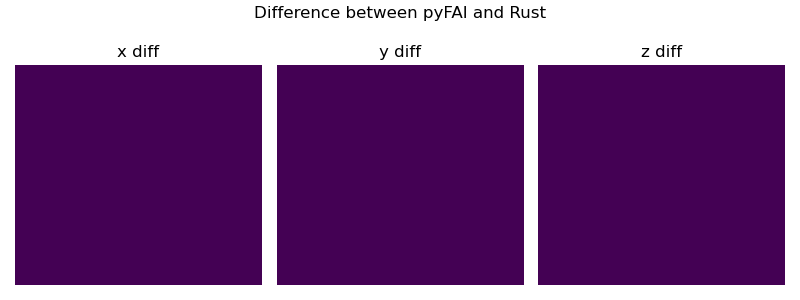

In [30]:
figure(figsize=(8, 3))
suptitle("Difference between pyFAI and Rust")
subplot(1, 3, 1)
title("x diff"); axis("off")
imshow(x-x_rust, origin="lower", aspect="auto")
subplot(1, 3, 2)
title("y diff"); axis("off")
imshow(y-y_rust, origin="lower", aspect="auto")
subplot(1, 3, 3)
title("z diff"); axis("off")
imshow(z-z_rust, origin="lower", aspect="auto")
tight_layout()

In [31]:
index = 0
print("Comparison Values at {}".format(index))
print(x.flatten()[index])
print(y.flatten()[index])
print(z.flatten()[index])

index = test_index
print("Comparison values at {}".format(index))
print(x.flatten()[index])
print(y.flatten()[index])
print(z.flatten()[index])

Comparison Values at 0
-0.1880643204202641
-0.0837083064488318
0.20636655782476682
Comparison values at 65
-0.1880651731674789
-0.07253020764574664
0.20657272867937088


## Two-Theta

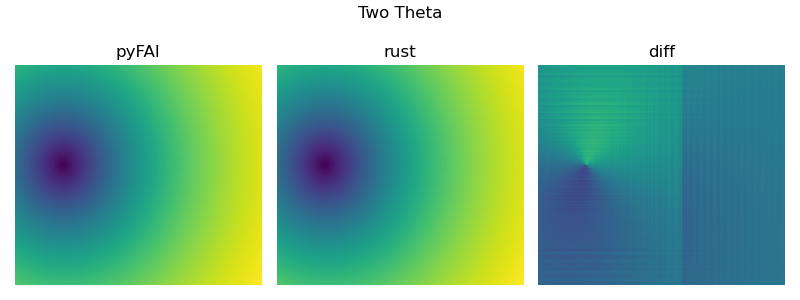

In [32]:
tth_rust = np.loadtxt("test_output/tth.txt").reshape(shape)
tth = geometry.twoThetaArray()
figure(figsize=(8, 3))
suptitle("Two Theta")
subplot(1, 3, 1)
title("pyFAI"); axis("off")
imshow(tth, origin="lower", aspect="auto")
subplot(1, 3, 2)
title("rust"); axis("off")
imshow(tth_rust, origin="lower", aspect="auto")
subplot(1, 3, 3)
title("diff"); axis("off")
imshow(tth_rust-tth, origin="lower", aspect="auto")
tight_layout()

In [33]:
index=0
print("Two Theta Value at {}: {}".format(index, tth.flatten()[index]))

index = test_index
print("Two Theta Value at {}: {}".format(index, tth.flatten()[index]))

Two Theta Value at 0: 0.7841512459252314
Two Theta Value at 65: 0.7731333594582992


## Azimuth Chi angle

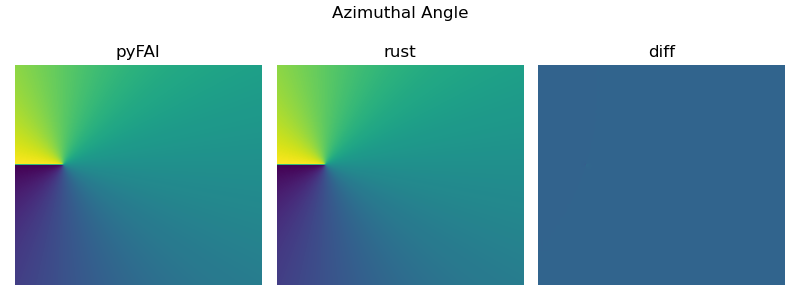

In [34]:
chi_rust = np.loadtxt("test_output/chi.txt").reshape(shape)
chi = geometry.chiArray()
figure(figsize=(8, 3))
suptitle("Azimuthal Angle")
subplot(1, 3, 1)
title("pyFAI"); axis("off")
imshow(chi, origin="lower", aspect="auto")
subplot(1, 3, 2)
title("rust"); axis("off")
imshow(chi_rust, origin="lower", aspect="auto")
subplot(1, 3, 3)
title("diff"); axis("off")
imshow(chi_rust-chi, origin="lower", aspect="auto")
tight_layout()

In [35]:
index=[0, test_index]
for i in index:
    print("Chi Value at {}: {}".format(i, chi.flatten()[i]))

Chi Value at 0: -1.9895718171402677
Chi Value at 65: -1.9388844248371555
